# Processamento de Linguagem Natural (PLN) — guia didático

Este notebook reúne, **em ordem de aprendizado**, todo o conteúdo prático das 6 aulas de PLN:

| Parte | Tema | O que você vai aprender |
|---|---|---|
| 1 | Fundamentos | Por que texto é difícil, Lei de Zipf, primeiras ferramentas (NLTK e spaCy) |
| 2 | Pré-processamento | Limpeza, tokenização, stemming, lematização, stop words |
| 3 | Vetorização clássica | Bag of Words, n-gramas, TF-IDF |
| 4 | Embeddings | Word2Vec, FastText, similaridade e analogias |
| 5 | Classificação e NER | Naive Bayes, Regressão Logística, Pipeline, GridSearch, entidades nomeadas |
| 6 | Modelagem de tópicos | LDA, pyLDAvis e BERTopic |

**Como usar**
1. Execute de cima para baixo (as células compartilham variáveis).
2. Cada parte começa com uma célula `%pip install`, que instala **somente** as bibliotecas usadas nela. Se uma célula de instalação alterar pacotes já carregados (ex.: `numpy`), reinicie o kernel e execute de novo — o que já foi instalado continua instalado.
3. Os dados são **sintéticos** (gerados na seção abaixo), então os números exatos podem diferir de um corpus real; o importante é entender o que cada técnica faz.

> Dica de estudo: antes de executar uma célula, tente prever a saída. Depois, mude um parâmetro por vez e observe o efeito.

---
# Parte 1 — Fundamentos

## 1.0 Preparando o ambiente

Instalamos aqui apenas o que a Parte 1 usa:

- `nltk` — biblioteca clássica de PLN (tokenização, stop words, stemmer);
- `spacy` — biblioteca moderna de PLN (tokenização, classes gramaticais, entidades);
- `scikit-learn` — vetorização de texto e modelos;
- `pandas`, `numpy`, `matplotlib` — tabelas, contas e gráficos.

In [1]:
# Instala apenas as bibliotecas da Parte 1 (-q = saída resumida)
%pip install -q nltk spacy scikit-learn pandas numpy matplotlib

In [2]:
# Importa as bibliotecas usadas nesta parte
import re
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import spacy
from spacy.cli import download as baixar_modelo_spacy

# Baixa os recursos do NLTK: tokenizador, stop words e stemmer em português
for recurso in ("punkt", "punkt_tab", "stopwords", "rslp"):
    nltk.download(recurso, quiet=True)

# Carrega o modelo de português do spaCy; se não estiver instalado, baixa e carrega
try:
    nlp = spacy.load("pt_core_news_lg")
except OSError:
    baixar_modelo_spacy("pt_core_news_lg")
    import pt_core_news_lg
    nlp = pt_core_news_lg.load()

print("Modelo spaCy carregado:", nlp.meta["name"], "| idioma:", nlp.meta["lang"])

Modelo spaCy carregado: core_news_lg | idioma: pt


## 1.1 Dados de exemplo (sintéticos)

Os slides assumem um corpus de *reviews* de produtos já pronto. Como ele não vem no repositório, **geramos um aqui**, uma única vez, e o reutilizamos em todas as partes:

- `reviews` — lista de 600 textos (cada um com 2 frases sobre entrega, produto, atendimento ou preço);
- `labels` — sentimento de cada review (`1` = positivo, `0` = negativo);
- ~10% das reviews são **mistas** (uma frase positiva e outra negativa), para o problema não ficar fácil demais.

Para usar o seu próprio corpus, basta substituir `reviews` e `labels`.

In [3]:
import random

random.seed(42)  # semente fixa: os mesmos dados a cada execução

# Frases-base organizadas por assunto e sentimento (1 = positivo, 0 = negativo)
frases = {
    "entrega": {
        1: ["A entrega foi muito rápida e chegou antes do prazo",
            "Pedido entregue em dois dias, tudo bem embalado",
            "O frete foi rápido e o entregador foi educado",
            "Chegou rapidinho, a entrega superou o esperado"],
        0: ["A entrega atrasou mais de uma semana",
            "O pedido chegou com a embalagem amassada",
            "Frete caro e a entrega demorou demais",
            "O entregador não apareceu e o prazo estourou"],
    },
    "produto": {
        1: ["O produto é excelente e funciona perfeitamente",
            "Qualidade ótima, o produto é igual ao anunciado",
            "Adorei o produto, material resistente e bonito",
            "Produto maravilhoso, superou as minhas expectativas"],
        0: ["O produto chegou quebrado e com defeito",
            "Qualidade ruim, o produto parou de funcionar em dois dias",
            "Material fraco, o produto não é como na foto",
            "Produto péssimo, muito decepcionado com a compra"],
    },
    "atendimento": {
        1: ["O atendimento foi excelente e resolveram tudo rápido",
            "Suporte atencioso, tiraram todas as minhas dúvidas",
            "Atendimento nota dez, vendedor muito educado",
            "A equipe de suporte foi ótima e muito prestativa"],
        0: ["O atendimento foi horrível e ninguém resolveu meu problema",
            "Suporte demorou dias para responder",
            "Atendente mal educado, não recomendo o suporte",
            "Esperei horas no telefone e o atendimento não ajudou"],
    },
    "preço": {
        1: ["O preço está ótimo e vale cada centavo",
            "Preço justo e promoção muito boa",
            "Custo benefício excelente, preço abaixo da concorrência",
            "Pagamento facilitado e preço muito bom"],
        0: ["O preço está abusivo para a qualidade",
            "Muito caro, o preço não vale o produto",
            "Preço alto e ainda cobraram taxa extra",
            "Não vale o preço, achei mais barato em outra loja"],
    },
}

assuntos = list(frases)
reviews, labels = [], []

for _ in range(600):
    sentimento = random.randint(0, 1)                 # sorteia positivo ou negativo
    assunto_1, assunto_2 = random.sample(assuntos, 2)  # dois assuntos diferentes
    frase_1 = random.choice(frases[assunto_1][sentimento])
    # 10% das reviews têm a 2ª frase com sentimento oposto (review "mista")
    sentimento_2 = 1 - sentimento if random.random() < 0.10 else sentimento
    frase_2 = random.choice(frases[assunto_2][sentimento_2])
    reviews.append(f"{frase_1}. {frase_2}.")
    labels.append(sentimento)                          # o rótulo segue a 1ª frase

# Confere o resultado
print(f"Total de reviews: {len(reviews)} | positivas: {sum(labels)} | negativas: {len(labels) - sum(labels)}")
for texto, rotulo in list(zip(reviews, labels))[:3]:
    print(f"[{rotulo}] {texto}")

Total de reviews: 600 | positivas: 314 | negativas: 286
[0] Frete caro e a entrega demorou demais. Suporte demorou dias para responder.
[0] O entregador não apareceu e o prazo estourou. O atendimento foi excelente e resolveram tudo rápido.
[0] O produto chegou quebrado e com defeito. Esperei horas no telefone e o atendimento não ajudou.


## 1.2 Por que texto é difícil? Polissemia

Computadores entendem números, não palavras. E uma mesma palavra pode ter **vários sentidos** (*polissemia*). "banco" pode ser instituição financeira, assento ou banco de dados.

Um modelo simples como o **Bag of Words** (contagem de palavras) não distingue esses sentidos: a palavra vira só uma coluna na tabela. Veja:

In [4]:
from sklearn.feature_extraction.text import CountVectorizer

# Três frases com a palavra "banco" em sentidos diferentes
frases_banco = [
    "O banco aprovou meu empréstimo ontem",        # sentido financeiro
    "Sentei no banco da praça para descansar",     # sentido de assento
    "O banco de dados PostgreSQL caiu novamente",  # sentido tecnológico
]

vec = CountVectorizer()                       # contador de palavras
X_banco = vec.fit_transform(frases_banco)     # gera a matriz documento-termo

print("Vocabulário:", list(vec.get_feature_names_out()))

# Mostra a matriz como tabela: linhas = frases, colunas = palavras
print(pd.DataFrame(X_banco.toarray(), columns=vec.get_feature_names_out()))

Vocabulário: ['aprovou', 'banco', 'caiu', 'da', 'dados', 'de', 'descansar', 'empréstimo', 'meu', 'no', 'novamente', 'ontem', 'para', 'postgresql', 'praça', 'sentei']
   aprovou  banco  caiu  da  dados  de  descansar  empréstimo  meu  no  \
0        1      1     0   0      0   0          0           1    1   0   
1        0      1     0   1      0   0          1           0    0   1   
2        0      1     1   0      1   1          0           0    0   0   

   novamente  ontem  para  postgresql  praça  sentei  
0          0      1     0           0      0       0  
1          0      0     1           0      1       1  
2          1      0     0           1      0       0  


**O que observar:** a coluna `banco` vale `1` nas três linhas. Para o Bag of Words os três "bancos" são idênticos — a informação de sentido se perdeu. Esse é o limite que os *embeddings* (Parte 4) ajudam a superar, porque levam o contexto em conta.

## 1.3 Lei de Zipf

Em qualquer idioma, **poucas palavras aparecem muitíssimas vezes** (de, a, o, que...) e **muitas palavras aparecem raramente**. Isso é a **Lei de Zipf**: a frequência de uma palavra é inversamente proporcional à sua posição no ranking.

Consequências práticas: stop words dominam a contagem e boa parte do vocabulário aparece só uma vez (palavras raras, erros de digitação). Vamos ver isso no nosso corpus:

10 palavras mais frequentes: [('o', 787), ('e', 554), ('produto', 350), ('preço', 299), ('a', 285), ('muito', 271), ('foi', 223), ('não', 222), ('atendimento', 164), ('suporte', 143)]
Palavras diferentes: 124 | aparecem só 1 vez: 0


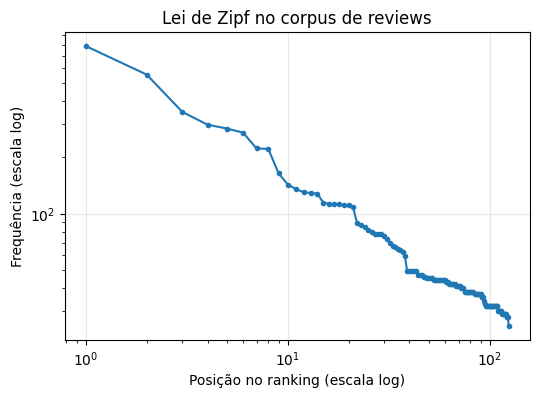

In [5]:
# Extrai todas as palavras (só letras, incluindo acentuadas) em minúsculas
palavras = re.findall(r"[a-záàâãéêíóôõúç]+", " ".join(reviews).lower())

contagem = Counter(palavras)                              # frequência de cada palavra
frequencias = sorted(contagem.values(), reverse=True)     # do mais ao menos frequente

print("10 palavras mais frequentes:", contagem.most_common(10))
print(f"Palavras diferentes: {len(contagem)} | aparecem só 1 vez: {sum(1 for v in contagem.values() if v == 1)}")

# Gráfico: posição no ranking x frequência, em escala log-log
plt.figure(figsize=(6, 4))
plt.loglog(range(1, len(frequencias) + 1), frequencias, marker="o", markersize=3)
plt.xlabel("Posição no ranking (escala log)")
plt.ylabel("Frequência (escala log)")
plt.title("Lei de Zipf no corpus de reviews")
plt.grid(True, alpha=0.3)
plt.show()

**Como ler o gráfico:** em escala log-log, um corpus real tende a formar uma linha quase reta descendo. O nosso é pequeno e artificial (cerca de 120 palavras diferentes, todas repetidas várias vezes), então a curva é mais "em degraus" e **nenhuma palavra aparece só uma vez** — num corpus real, cerca de metade do vocabulário aparece apenas uma vez. Mesmo assim o padrão é visível: `o`, `e`, `produto` e `preço` no topo, e uma cauda de palavras bem menos frequentes.

## 1.4 Primeiras ferramentas: NLTK e spaCy

- **NLTK** — "caixa de ferramentas" clássica, ótima para aprender.
- **spaCy** — padrão da indústria: rápido e já entrega *lema*, classe gramatical (POS) e entidades.

Primeiro, tokenizar e contar com o NLTK usando um corpus pequeno de exemplo:

In [6]:
from nltk.tokenize import word_tokenize

# Corpus pequeno e fictício (a 5ª frase é uma ironia: difícil para qualquer modelo)
corpus_exemplo = [
    "O produto é excelente, recomendo muito! Chegou rápido.",
    "Péssimo, o aparelho veio com defeito. Não comprem.",
    "Ótima qualidade pelo preço. Entrega rápida e bem embalado.",
    "Adorei! Funciona perfeitamente, superou minhas expectativas.",
    "Esperei 3 horas no telefone. Adorei o atendimento.",
]

# Tokeniza cada documento (minúsculas + regras do português) e junta tudo numa lista
todos_tokens = []
for doc in corpus_exemplo:
    todos_tokens.extend(word_tokenize(doc.lower(), language="portuguese"))

print(f"Total de tokens: {len(todos_tokens)} | vocabulário (únicos): {len(set(todos_tokens))}")

# Os mais frequentes: pontuação e stop words costumam dominar (Lei de Zipf)
for palavra, freq in Counter(todos_tokens).most_common(8):
    print(f"  {palavra:12s} -> {freq}")

Total de tokens: 52 | vocabulário (únicos): 39
  .            -> 8
  o            -> 3
  ,            -> 3
  !            -> 2
  adorei       -> 2
  produto      -> 1
  é            -> 1
  excelente    -> 1


**O que observar:** os tokens mais frequentes são pontuação (`.`, `,`, `!`) e palavras gramaticais (`o`, `e`). Elas quase não carregam significado — por isso, no pré-processamento (Parte 2), removemos stop words.

Agora o spaCy: uma única chamada `nlp(texto)` devolve tokens, **lema** (forma de dicionário), **POS** (classe gramatical) e **DEP** (função sintática).

In [7]:
# O spaCy processa o texto inteiro de uma vez
doc = nlp("O João comprou um livro na Amazon ontem.")

# Cabeçalho da tabela
print(f"{'TOKEN':12s} {'LEMA':12s} {'POS':8s} {'DEP':8s}")
print("-" * 44)

# Para cada token: texto original, lema, classe gramatical e dependência
for token in doc:
    print(f"{token.text:12s} {token.lemma_:12s} {token.pos_:8s} {token.dep_:8s}")

TOKEN        LEMA         POS      DEP     
--------------------------------------------
O            o            DET      det     
João         João         PROPN    nsubj   
comprou      comprar      VERB     ROOT    
um           um           DET      det     
livro        livro        NOUN     obj     
na           em o         ADP      case    
Amazon       Amazon       PROPN    obl     
ontem        ontem        ADV      advmod  
.            .            PUNCT    punct   


**Como ler:** `comprou` tem lema `comprar` (verbo no infinitivo), `João` é `PROPN` (nome próprio) e `livro` é `NOUN` (substantivo). Note que `na` vira `em o` no lema: o spaCy desfaz a contração.

O spaCy também reconhece **entidades nomeadas** (NER): pessoas (`PER`), lugares (`LOC`), organizações (`ORG`) e outros (`MISC`).

In [8]:
texto_ner = ("Leonardo da Vinci nasceu em Vinci, Itália, em 1452. "
             "Foi pintor, cientista e trabalhou para Lorenzo de Médici. "
             "Morreu em Amboise, na França.")

doc = nlp(texto_ner)

# doc.ents contém as entidades encontradas; label_ é o tipo de cada uma
print("Entidades encontradas:")
for ent in doc.ents:
    print(f"  {ent.text:22s} -> {ent.label_}")

Entidades encontradas:
  Leonardo da Vinci      -> PER
  Vinci                  -> LOC
  Itália                 -> LOC
  Lorenzo de Médici      -> PER
  Amboise                -> LOC
  França                 -> LOC


**Observação:** o modelo é estatístico e pode **errar ou deixar entidades de fora** (por exemplo, a data `1452` pode não ser marcada). Pessoas e lugares costumam ser reconhecidos com boa confiança. Retomaremos NER com mais detalhe na Parte 5.

Por fim, a **primeira vetorização**: transformar texto em números com *Bag of Words*, já removendo stop words.

In [9]:
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer

stopwords_pt = stopwords.words("portuguese")        # lista de stop words em português

# Bag of Words ignorando as stop words
vec = CountVectorizer(stop_words=stopwords_pt)
X_exemplo = vec.fit_transform(corpus_exemplo)

print(f"Formato da matriz: {X_exemplo.shape}  (documentos x palavras do vocabulário)")

# Matriz documento-termo como tabela (primeiras 8 colunas)
df_dt = pd.DataFrame(X_exemplo.toarray(), columns=vec.get_feature_names_out())
print(df_dt.iloc[:, :8])

Formato da matriz: (5, 26)  (documentos x palavras do vocabulário)
   adorei  aparelho  atendimento  bem  chegou  comprem  defeito  embalado
0       0         0            0    0       1        0        0         0
1       0         1            0    0       0        1        1         0
2       0         0            0    1       0        0        0         1
3       1         0            0    0       0        0        0         0
4       1         0            1    0       0        0        0         0


**Como ler:** cada linha é um documento, cada coluna uma palavra, e o valor é quantas vezes ela aparece. É a representação mais simples de texto para um modelo de Machine Learning. Vamos refiná-la na Parte 3.

---
# Parte 2 — Pré-processamento de texto

Texto real é "sujo": tem HTML, links, gírias, erros e emojis. O pré-processamento **limpa e padroniza** o texto antes de qualquer modelo. A ordem típica é:

`limpar` → `normalizar` → `tokenizar` → `remover stop words` → `reduzir à raiz (stemming ou lematização)`

Nesta parte não precisamos instalar nada novo, exceto o `transformers` (usado só para ver como modelos modernos tokenizam).

In [ ]:
# Instala apenas o que é novo nesta parte: transformers (tokenizador do BERTimbau)
%pip install -q transformers

## 2.1 Limpeza com expressões regulares (regex)

*Regex* é uma "linguagem de padrões" para achar e trocar trechos de texto. Mostramos cada passo para você ver o efeito:

In [ ]:
texto = "<p>Adorei!! https://link.com vc tem que ver isso :)</p>"
print("Original         :", texto)

# 1) Remove tags HTML: tudo entre < e >
limpo = re.sub(r"<[^>]+>", " ", texto)
print("Sem HTML         :", limpo)

# 2) Remove URLs: http... ou www... até o próximo espaço
limpo = re.sub(r"http\S+|www\.\S+", " ", limpo)
print("Sem URL          :", limpo)

# 3) Remove e-mails
limpo = re.sub(r"\S+@\S+", " ", limpo)

# 4) Mantém só letras (com acento) e espaços
limpo = re.sub(r"[^a-záàâãäéèêëíìîïóòôõöúùûüç\s]", " ", limpo)
print("Só letras        :", limpo)

# 5) Colapsa espaços repetidos e tira espaços das pontas
limpo = re.sub(r"\s+", " ", limpo).strip()
print("Espaços ajustados:", limpo)

## 2.2 Contrações e gírias de internet

Em reviews é comum ver `vc`, `tbm`, `pq`. Um **dicionário de contrações** troca cada abreviação pela forma completa, para o modelo tratar `vc` e `você` como a mesma palavra.

In [ ]:
# Mapa de abreviações comuns do português informal
CONTRACOES = {
    "vc": "você", "tb": "também", "tbm": "também", "pq": "por que",
    "obg": "obrigado", "blz": "beleza", "td": "tudo", "msm": "mesmo",
    "vlw": "valeu", "n": "não", "naum": "não", "cmprar": "comprar",
    "mt": "muito", "pra": "para",
}

# Reviews "sujas", como as reais (HTML, emoji, links, gírias, erros)
reviews_sujas = [
    "<p>ADOREI o produto!! vc precisa cmprar tbm 😍</p>",
    "Pessimo!! veio quebrado >:( https://reclame.com",
    "Mt bom mesmo, entrega rapida! 5 estrelas pra esse vendedor.",
    "Não gostei :( voltei o item, atendimento foi pessimo tbm.",
]

def limpar_texto(texto):
    """Limpeza básica: minúsculas, sem HTML/URL/e-mail e com contrações expandidas."""
    texto = texto.lower()                              # 1. minúsculas
    texto = re.sub(r"<[^>]+>", " ", texto)             # 2. remove HTML
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)    # 3. remove URLs
    texto = re.sub(r"\S+@\S+", " ", texto)             # 4. remove e-mails
    palavras = [CONTRACOES.get(p, p) for p in texto.split()]  # 5. expande contrações
    return " ".join(palavras)

print(limpar_texto(reviews_sujas[0]))

## 2.3 Acentos: quando remover?

Remover acentos (`São Paulo` → `Sao Paulo`) **ajuda em busca** (o usuário digita sem acento) mas **atrapalha em NER** (o modelo usa a grafia correta para reconhecer nomes). A decisão depende do uso final do texto.

A técnica usa a normalização Unicode `NFKD`, que separa a letra do acento; depois descartamos as marcas de acento.

In [ ]:
import unicodedata

def remove_acentos(texto):
    """Remove acentos: 'coração' -> 'coracao'. Útil para busca; perigoso para NER."""
    decomposto = unicodedata.normalize("NFKD", texto)                 # separa letra e acento
    return "".join(c for c in decomposto if not unicodedata.combining(c))  # descarta os acentos

for exemplo in ["São Paulo", "experiência", "coração"]:
    print(f"{exemplo:12s} -> {remove_acentos(exemplo)}")

## 2.4 Pipeline de limpeza completo

Juntamos tudo em **uma função modular**, com a remoção de acentos opcional. Funções assim são fáceis de testar e de reutilizar em outros projetos.

In [ ]:
def limpar_normalizar(texto, remover_acentos=False):
    """Pipeline de limpeza para texto em PT-BR."""
    if not isinstance(texto, str):                                   # protege contra valores nulos
        return ""
    texto = texto.lower()                                            # 1. minúsculas
    texto = re.sub(r"<[^>]+>", " ", texto)                           # 2. HTML
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)                  # 3. URLs
    texto = re.sub(r"\S+@\S+", " ", texto)                           # 4. e-mails
    texto = " ".join(CONTRACOES.get(p, p) for p in texto.split())    # 5. contrações
    texto = re.sub(r"[^a-záàâãäéèêëíìîïóòôõöúùûüç\s.,!?]", " ", texto)  # 6. mantém letras e pontuação básica
    if remover_acentos:                                              # 7. acentos (opcional)
        texto = remove_acentos(texto)
    return re.sub(r"\s+", " ", texto).strip()                        # 8. espaços

sujo = "<p>Adorei o produto!! https://exemplo.com VC PRECISA TBM!!!</p>"
print("Antes :", sujo)
print("Depois:", limpar_normalizar(sujo))
print()
for r in reviews_sujas:
    print(limpar_normalizar(r))

## 2.5 Tokenização

**Tokenizar** é quebrar o texto em unidades (tokens). Há três famílias:

1. `split()` — ingênuo, só divide por espaço (serve de baseline didático);
2. **NLTK** `word_tokenize` — respeita abreviações e pontuação;
3. **spaCy** — tokeniza e já entrega lema, POS e dependências.

Compare o resultado no mesmo texto:

In [ ]:
from nltk.tokenize import word_tokenize, sent_tokenize

texto = "O Sr. Silva, hoje, tem R$ 1.250,99 no banco!"

# 1) split(): a pontuação fica grudada nas palavras ("Silva," e "banco!")
print("split()  :", texto.split())

# 2) NLTK: separa a pontuação e mantém "Sr." e "1.250,99" inteiros
print("NLTK     :", word_tokenize(texto, language="portuguese"))

# 3) spaCy: tokens + lema + classe gramatical
print("spaCy    :", [(t.text, t.lemma_, t.pos_) for t in nlp(texto)])

**O que observar:** com `split()`, `Silva,` e `Silva` seriam tokens diferentes no vocabulário — um problema sério. Em produção, **nunca use `split()` puro**.

### Tokenização de frases

Às vezes precisamos quebrar em **frases**, não em palavras. O ponto final nem sempre indica fim de frase (`Sr.`), então usamos um modelo treinado.

In [ ]:
texto_frases = ("Adorei o produto. Chegou rápido! "
                "Recomendo a todos. Mas o preço foi alto...")

# NLTK: lista de frases
for i, frase in enumerate(sent_tokenize(texto_frases, language="portuguese"), 1):
    print(f"{i}. {frase}")

# spaCy: a segmentação em frases (.sents) já vem pronta
print("--- spaCy ---")
for frase in nlp(texto_frases).sents:
    print(frase.text)

### Subwords e BPE (Byte-Pair Encoding)

Modelos modernos (BERT, GPT) não usam palavras inteiras: usam **subwords**. Assim, uma palavra rara é quebrada em pedaços conhecidos e nunca vira "desconhecida". O algoritmo **BPE** faz isso:

1. começa com cada **caractere** como um símbolo;
2. conta qual **par de símbolos vizinhos** aparece mais;
3. **funde** esse par em um símbolo novo;
4. repete até ter um vocabulário do tamanho desejado.

Mini-implementação com um vocabulário de brinquedo (`</w>` marca o fim da palavra):

In [ ]:
# Vocabulário de brinquedo: palavra (separada em símbolos) -> frequência no corpus
vocab_bpe = {"l o w </w>": 5, "l o w e r </w>": 2,
             "n e w e s t </w>": 6, "w i d e s t </w>": 3}

def contar_pares(vocab):
    """Conta a frequência de cada par de símbolos vizinhos."""
    pares = Counter()
    for palavra, freq in vocab.items():
        simbolos = palavra.split()
        for a, b in zip(simbolos, simbolos[1:]):   # pares (1º,2º), (2º,3º)...
            pares[(a, b)] += freq
    return pares

def fundir_par(par, vocab):
    """Funde o par escolhido em um único símbolo em todas as palavras."""
    novo_vocab = {}
    for palavra, freq in vocab.items():
        simbolos, i, resultado = palavra.split(), 0, []
        while i < len(simbolos):
            if i < len(simbolos) - 1 and (simbolos[i], simbolos[i + 1]) == par:
                resultado.append(simbolos[i] + simbolos[i + 1])  # funde os dois
                i += 2
            else:
                resultado.append(simbolos[i])
                i += 1
        novo_vocab[" ".join(resultado)] = freq
    return novo_vocab

# Executa 8 rodadas de fusão, mostrando o par mais frequente de cada uma
for rodada in range(1, 9):
    pares = contar_pares(vocab_bpe)
    melhor = max(pares, key=pares.get)             # par mais frequente
    vocab_bpe = fundir_par(melhor, vocab_bpe)
    print(f"Rodada {rodada}: funde {melhor} (freq. {pares[melhor]})")

print("\nPalavras ao final:", list(vocab_bpe))

**Como ler:** a cada rodada, pares frequentes como `e`+`s` viram `es`, depois `est`, e assim surgem subwords úteis (`est`, `low`...). Com um corpus enorme, o resultado são subwords como `##ando`, `##mente`.

Veja como um modelo real, o **BERTimbau** (BERT em português), tokeniza. *(Baixa só o vocabulário do tokenizador, algo pequeno; precisa de internet.)*

In [ ]:
try:
    from transformers import AutoTokenizer

    tok = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")
    # "##" indica que o pedaço continua a palavra anterior
    print(tok.tokenize("correríamos pela praia"))
    print(tok.tokenize("inconstitucionalissimamente"))
except Exception as erro:
    # Sem internet o download falha; o restante do notebook segue normalmente
    print("Não foi possível carregar o tokenizador (precisa de internet):", erro)

**Curiosidade:** palavras comuns viram 1 token; palavras longas e raras são quebradas em vários pedaços. Por isso GPT e BERT parecem "tokenizar de forma estranha" — é uma troca entre vocabulário pequeno e sequências curtas.

## 2.6 Stemming x Lematização

Ambos reduzem palavras à forma-base para agrupar variações (`correndo`, `correu`, `correriam`):

| | Stemming | Lematização |
|---|---|---|
| Como | corta sufixos por regras | usa dicionário e gramática |
| Resultado | pode não ser palavra (`corr`) | sempre palavra válida (`correr`) |
| Velocidade | muito rápida | mais lenta |
| Exemplo no código | `RSLPStemmer` (NLTK) | `token.lemma_` (spaCy) |

In [ ]:
from nltk.stem import RSLPStemmer

stemmer = RSLPStemmer()   # stemmer feito para o português (RSLP)

exemplos = ["correndo", "correu", "correriam", "maravilhoso",
            "felicidades", "menino", "meninas", "casinha", "gatos"]

print("STEMMING (corta o final da palavra)")
for palavra in exemplos:
    print(f"  {palavra:14s} -> {stemmer.stem(palavra)}")

In [ ]:
# LEMATIZAÇÃO com spaCy: devolve a forma de dicionário
doc = nlp("As crianças estavam correndo felizes pela praia maravilhosa.")

print("LEMATIZAÇÃO (forma de dicionário)")
for token in doc:
    print(f"  {token.text:14s} -> {token.lemma_}")

**O que observar:** o stemmer produz `corr` e `maravilh` (pedaços), enquanto o lematizador devolve `correr` e `maravilhoso`. Use **stemming** quando velocidade importa (busca, classificação simples) e **lematização** quando o significado importa.

## 2.7 Stop words

*Stop words* são palavras muito frequentes e de pouco conteúdo (`o`, `de`, `que`). Removê-las reduz ruído e tamanho. **Cuidado:** em análise de sentimento, `não` é uma stop word que **inverte o sentido** — avalie caso a caso.

In [ ]:
from nltk.corpus import stopwords

STOP_WORDS_PT = set(stopwords.words("portuguese"))   # set = busca rápida

print(f"Total: {len(STOP_WORDS_PT)} stop words")
print("Exemplos:", sorted(STOP_WORDS_PT)[:15])
print("'não' é stop word?", "não" in STOP_WORDS_PT)   # atenção: muda o sentido da frase

## 2.8 Pipeline de PLN final

Agora costuramos tudo em uma função: **limpar → tokenizar → remover stop words → (stemming opcional)**. O parâmetro `usar_stemming` permite reaproveitar a mesma função para tarefas diferentes.

In [ ]:
def pipeline_nlp(textos, usar_stemming=True):
    """Lista de textos PT -> lista de listas de tokens limpos."""
    resultado = []
    for texto in textos:
        texto = limpar_normalizar(texto)                                   # 1. limpeza
        tokens = word_tokenize(texto, language="portuguese")               # 2. tokenização
        tokens = [t for t in tokens                                        # 3. só palavras, sem stop words
                  if t.isalpha() and t not in STOP_WORDS_PT and len(t) > 2]
        if usar_stemming:                                                  # 4. stemming (opcional)
            tokens = [stemmer.stem(t) for t in tokens]
        resultado.append(tokens)
    return resultado

exemplo = ["Adorei o produto, entrega rapidíssima!",
           "Não gostei, veio quebrado e atrasado."]
print("Com stemming :", pipeline_nlp(exemplo))
print("Sem stemming :", pipeline_nlp(exemplo, usar_stemming=False))

# Aplica ao corpus completo SEM stemming: palavras legíveis (usadas em Word2Vec e LDA, Partes 4 e 6)
tokens_limpos = pipeline_nlp(reviews, usar_stemming=False)
print("\nPrimeira review tokenizada:", tokens_limpos[0])

**O que observar:** note que `não` desaparece (é stop word) — por isso, para classificar sentimento, usaremos o texto original (`reviews`) com n-gramas. Já `tokens_limpos` (palavras legíveis, sem stemming) servirá para embeddings e tópicos.

---

# Parte 3 — Vetorização clássica: Bag of Words, n-gramas e TF-IDF

Modelos precisam de **números**. Vetorizar é converter cada texto em um vetor. As técnicas clássicas contam palavras:

- **Bag of Words (BoW):** quantas vezes cada palavra aparece;
- **n-gramas:** também contam sequências de palavras (`não gostei`);
- **TF-IDF:** dá mais peso a palavras *raras e informativas* do que a palavras que aparecem em todo lugar.

In [ ]:
# Instala apenas o que é novo nesta parte: scipy (matrizes esparsas)
%pip install -q scipy

## 3.1 Bag of Words "na mão"

Antes de usar a biblioteca, vamos construir o BoW passo a passo para entender o que acontece por dentro: **vocabulário** → **contagem por documento** → **matriz**.

In [ ]:
from collections import Counter

corpus_bow = [
    "Adorei o produto, entrega rápida",
    "Produto chegou quebrado",
    "Entrega rápida, atendimento bom",
]

# 1) Tokeniza de forma simples: minúsculas, sem vírgula, separando por espaço
docs_tokens = [doc.lower().replace(",", "").split() for doc in corpus_bow]

# 2) Vocabulário = todas as palavras únicas, em ordem alfabética
vocab = sorted(set(t for doc in docs_tokens for t in doc))
print(f"Vocabulário ({len(vocab)} palavras):", vocab)

# 3) Matriz documento-termo: uma linha por documento, uma coluna por palavra
matriz = []
for tokens in docs_tokens:
    contagem = Counter(tokens)                           # conta as palavras do documento
    matriz.append([contagem.get(p, 0) for p in vocab])   # 0 quando a palavra não aparece

print(pd.DataFrame(matriz, columns=vocab))

## 3.2 Bag of Words com scikit-learn

O `CountVectorizer` faz os três passos acima de uma vez (e mais: minúsculas, filtros, n-gramas).

In [ ]:
corpus_sk = [
    "Adorei o produto, entrega rápida e qualidade boa.",
    "Produto chegou quebrado, qualidade péssima.",
    "Entrega rápida, atendimento bom, recomendo!",
    "Produto bom mas atendimento péssimo.",
]

vectorizer = CountVectorizer(lowercase=True, max_features=20)  # no máximo 20 palavras no vocabulário
X_sk = vectorizer.fit_transform(corpus_sk)                    # aprende o vocabulário e conta
vocab_sk = vectorizer.get_feature_names_out()

print(pd.DataFrame(X_sk.toarray(), columns=vocab_sk))
print("Tamanho do vocabulário:", len(vocab_sk))
print(f"Esparsidade: {1 - X_sk.nnz / (X_sk.shape[0] * X_sk.shape[1]):.2%}")  # % de zeros

**Como ler:** cada linha é um documento e cada coluna uma palavra. Repare em quantos zeros a tabela tem — isso se chama **esparsidade**.

## 3.3 Esparsidade e matrizes esparsas

Em corpora reais, o vocabulário tem dezenas de milhares de palavras, mas cada texto usa poucas dezenas. A matriz fica **quase toda zero**. Guardar todos os zeros desperdiça memória, então usamos **matrizes esparsas** (`scipy.sparse`), que guardam só os valores diferentes de zero.

Vamos medir no nosso corpus de 600 reviews:

In [ ]:
X_reviews = CountVectorizer().fit_transform(reviews)   # matriz esparsa (scipy) com todas as reviews

total_celulas = X_reviews.shape[0] * X_reviews.shape[1]
print(f"Formato: {X_reviews.shape}  (reviews x palavras)")
print(f"Total de células: {total_celulas:,} | não-zeros: {X_reviews.nnz:,}")
print(f"Esparsidade: {1 - X_reviews.nnz / total_celulas:.2%}")

# Memória: matriz densa (numpy) x matriz esparsa (scipy)
bytes_densa = X_reviews.toarray().nbytes
bytes_esparsa = X_reviews.data.nbytes + X_reviews.indices.nbytes + X_reviews.indptr.nbytes
print(f"Memória densa : {bytes_densa / 1024:.0f} KB")
print(f"Memória esparsa: {bytes_esparsa / 1024:.0f} KB")

**O que observar:** a matriz esparsa ocupa uma fração da densa. Com 600 reviews a diferença é pequena; com 10 mil documentos e 30 mil palavras a densa passaria de **2 GB** e a esparsa ficaria em dezenas de MB.

Os modelos do scikit-learn **aceitam matrizes esparsas diretamente**. Só converta para densa (`.toarray()`) para visualizar coisas pequenas:

In [ ]:
from scipy.sparse import csr_matrix                      # tipo de matriz esparsa usado pelo scikit-learn
from sklearn.linear_model import LogisticRegression

print("Tipo de X:", type(X_sk))                          # já é scipy.sparse

y_sk = [1, 0, 1, 0]                                      # rótulos das 4 reviews do corpus_sk (1 = positiva)
modelo_sk = LogisticRegression()
modelo_sk.fit(X_sk, y_sk)                                # funciona direto, sem converter para densa
print("Treinou com matriz esparsa. Classes:", modelo_sk.classes_)

X_denso = X_sk.toarray()                                 # conversão para densa: só com matrizes pequenas!
print("Formato como array denso:", X_denso.shape)

## 3.4 N-gramas: capturando contexto

Um **n-grama** é uma sequência de *n* palavras. Com unigramas (n=1) perdemos a ordem: `não gostei` vira `não` + `gostei`. Com **bigramas** (n=2) e **trigramas** (n=3) guardamos expressões como `não gostei` e `muito bom mesmo`.

Veja o vocabulário com `ngram_range=(3, 3)` (só trigramas):

In [ ]:
textos = ["não gostei nada do produto",
          "muito bom mesmo, recomendo",
          "foi de jeito nenhum"]

vec_tri = CountVectorizer(ngram_range=(3, 3))            # apenas trigramas
vec_tri.fit(textos)
print(list(vec_tri.get_feature_names_out()))

Normalmente combinamos unigramas **e** bigramas com `ngram_range=(1, 2)`. Compare quantas *features* (colunas) cada configuração gera:

In [ ]:
corpus_ng = [
    "Adorei o produto, super recomendo",
    "Não gostei muito do produto",
    "Produto bom mesmo, vale o preço",
    "Muito ruim, não comprem",
]

for faixa in [(1, 1), (1, 2), (1, 3), (2, 2)]:
    vec = CountVectorizer(ngram_range=faixa)
    n_features = vec.fit_transform(corpus_ng).shape[1]
    print(f"ngram_range={faixa}: {n_features} features")

**O que observar:** o número de colunas cresce rápido com n-gramas. Por isso usamos **filtros** para podar termos inúteis:

- `min_df=5` — ignora termos que aparecem em menos de 5 documentos (erros, raridades);
- `max_df=0.85` — ignora termos presentes em mais de 85% dos documentos (quase stop words);
- `max_features=10000` — mantém só os 10 mil termos mais frequentes.

In [ ]:
# Sem filtros: todos os unigramas e bigramas
sem_filtro = CountVectorizer(ngram_range=(1, 2)).fit_transform(reviews)

# Com filtros: poda termos raros e universais
com_filtro = CountVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.85,
                             max_features=10000).fit_transform(reviews)

print("Features sem filtros:", sem_filtro.shape[1])
print("Features com filtros:", com_filtro.shape[1])

### N-gramas na prática: análise de sentimento

Vamos medir se bigramas ajudam a classificar o sentimento. Usamos **validação cruzada** (`cross_val_score`): o modelo é treinado e testado em 5 partes diferentes dos dados, o que dá uma nota mais confiável do que um único teste. A métrica é o **F1**, que equilibra precisão e revocação.

In [ ]:
from sklearn.model_selection import cross_val_score

# Só unigramas (palavras isoladas)
X_uni = CountVectorizer(ngram_range=(1, 1), min_df=5).fit_transform(reviews)
f1_uni = cross_val_score(LogisticRegression(max_iter=1000), X_uni, labels,
                         cv=5, scoring="f1").mean()

# Unigramas + bigramas
X_bi = CountVectorizer(ngram_range=(1, 2), min_df=5).fit_transform(reviews)
f1_bi = cross_val_score(LogisticRegression(max_iter=1000), X_bi, labels,
                        cv=5, scoring="f1").mean()

print(f"Só unigramas      : F1 = {f1_uni:.3f}")
print(f"Unigramas+bigramas: F1 = {f1_bi:.3f}")
print(f"Diferença: {(f1_bi - f1_uni) * 100:+.1f} pontos")

**Como ler:** em textos reais, bigramas costumam trazer alguns pontos de ganho porque capturam negações (`não gostei`) e intensificadores (`muito bom`). No nosso corpus sintético a diferença pode ser pequena, pois as frases são simples.

## 3.5 TF-IDF: dando peso à informação

O BoW trata todas as palavras como igualmente importantes, mas `produto` (que aparece em quase toda review) diz pouco, e `quebrado` diz muito. O **TF-IDF** corrige isso multiplicando duas partes:

- **TF (Term Frequency):** frequência da palavra *no documento* (quanto mais, maior);
- **IDF (Inverse Document Frequency):** `log(N / df)` — quanto *mais raro* nos documentos, maior.

`TF-IDF = TF × IDF` → palavra frequente **neste** documento e rara **nos outros** recebe peso alto.

### TF (frequência normalizada)

In [ ]:
def tf(palavra, doc):
    """Term Frequency: ocorrências da palavra / total de palavras do documento."""
    palavras = doc.split()
    return palavras.count(palavra) / len(palavras)

doc = "o produto bom o produto rápido"   # 6 palavras
for p in ["o", "produto", "bom", "rápido"]:
    print(f"TF({p}) = {tf(p, doc):.3f}")

### IDF (raridade entre os documentos)

`df` é em quantos documentos a palavra aparece. Se aparece em **todos**, `log(N/N) = 0`: a palavra não ajuda a distinguir documentos.

In [ ]:
import numpy as np

def idf(palavra, corpus):
    """Inverse Document Frequency: log(total de docs / docs que contêm a palavra)."""
    df = sum(1 for doc in corpus if palavra in doc.split())
    return np.log(len(corpus) / df) if df > 0 else 0

corpus_idf = ["o produto bom", "o produto ruim", "o produto quebrado", "o produto rápido"]
for p in ["o", "produto", "bom"]:
    print(f"IDF({p}) = {idf(p, corpus_idf):.3f}")

**Como ler:** `o` e `produto` estão nos 4 documentos → IDF = 0 (sem poder de distinção). `bom` aparece em 1 de 4 → IDF ≈ 1,39.

### TF-IDF completo, "na mão"

In [ ]:
corpus_tfidf = [
    "produto bom rapida entrega",
    "produto ruim quebrado",
    "entrega rapida atendimento bom",
    "atendimento ruim produto bom",
]

# Vocabulário ordenado (colunas da tabela)
vocab_tfidf = sorted(set(p for doc in corpus_tfidf for p in doc.split()))

# Cada célula = TF da palavra no documento x IDF da palavra no corpus
matriz_tfidf = [[tf(p, doc) * idf(p, corpus_tfidf) for p in vocab_tfidf]
                for doc in corpus_tfidf]

print(pd.DataFrame(matriz_tfidf, columns=vocab_tfidf).round(3))

**Como ler a tabela:** repare como a mesma palavra tem pesos **diferentes** em cada documento. `produto` está em 3 dos 4 documentos, então pesa pouco. `quebrado` aparece em apenas 1 documento, então recebe o maior peso daquela linha — é exatamente a palavra que sinaliza o problema.

### TfidfVectorizer: a versão para uso real

O `TfidfVectorizer` faz tudo isso (com pequenas melhorias, como `sublinear_tf`, que aplica `log(1+TF)` para que repetições excessivas não dominem):

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),     # unigramas + bigramas
    min_df=5,               # ignora termos em menos de 5 documentos
    max_df=0.85,            # ignora termos em mais de 85% dos documentos
    max_features=10000,     # limite do vocabulário
    sublinear_tf=True,      # suaviza repetições: usa log(1 + TF)
)
X_tfidf_all = vectorizer_tfidf.fit_transform(reviews)

print("Formato:", X_tfidf_all.shape, "| não-zeros:", X_tfidf_all.nnz)

# Top 5 termos de maior peso na primeira review
nomes = vectorizer_tfidf.get_feature_names_out()
pesos_doc0 = X_tfidf_all[0].toarray().flatten()
top_idx = np.argsort(pesos_doc0)[-5:][::-1]
print("Review 0:", reviews[0])
print("Top 5 termos do documento:")
for i in top_idx:
    print(f"  {nomes[i]:25s} {pesos_doc0[i]:.3f}")

### BoW x TF-IDF na tarefa real

Qual vetorização leva a um classificador melhor? Comparamos com a mesma validação cruzada:

In [ ]:
# 1) Bag of Words (contagem)
X_bow = CountVectorizer(ngram_range=(1, 2), min_df=5).fit_transform(reviews)
f1_bow = cross_val_score(LogisticRegression(max_iter=1000), X_bow, labels,
                         cv=5, scoring="f1").mean()

# 2) TF-IDF (peso por raridade)
X_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True).fit_transform(reviews)
f1_tfidf = cross_val_score(LogisticRegression(max_iter=1000), X_tfidf, labels,
                           cv=5, scoring="f1").mean()

print(f"BoW    F1: {f1_bow:.3f}")
print(f"TF-IDF F1: {f1_tfidf:.3f}")

**Como ler:** em geral o TF-IDF empata ou vence o BoW. Em corpus sintéticos simples a diferença é pequena; em textos reais, com muitas palavras comuns, o TF-IDF costuma ajudar mais.

---
# Parte 4 — Embeddings: vetores que carregam significado

Bag of Words e TF-IDF são **esparsos** e não entendem sentido (`carro` e `automóvel` são colunas sem relação). **Embeddings** são vetores **densos** (poucas centenas de números) aprendidos de modo que **palavras com significados parecidos fiquem próximas** no espaço vetorial.

> Ideia central: *"você conhece uma palavra pela companhia que ela mantém"* — palavras que aparecem em contextos parecidos ganham vetores parecidos.

A proximidade é medida pela **similaridade do cosseno** (ângulo entre vetores): 1 = mesma direção, 0 = sem relação.

In [ ]:
# Instala apenas o que é novo nesta parte: gensim (Word2Vec e FastText)
%pip install -q gensim

## 4.1 Intuição: similaridade do cosseno

Exemplo com vetores **inventados** de 4 dimensões (embeddings reais têm 100–300):

In [ ]:
def cosseno(a, b):
    """Similaridade do cosseno: produto escalar dividido pelo produto das normas."""
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

vec_rei     = np.array([0.42, -0.13, 0.78, 0.21])
vec_rainha  = np.array([0.41, -0.18, 0.75, 0.19])
vec_abacaxi = np.array([-0.31, 0.62, 0.04, -0.55])

print(f"rei x rainha  : {cosseno(vec_rei, vec_rainha):+.2f}   <- muito parecidos")
print(f"rei x abacaxi : {cosseno(vec_rei, vec_abacaxi):+.2f}   <- sem relação (ou opostos)")

## 4.2 Treinando Word2Vec com gensim

O **Word2Vec** aprende embeddings prevendo palavras a partir do contexto. Usamos o modo **Skip-gram** (`sg=1`): dada uma palavra, prevê as vizinhas. Treinamos nas nossas reviews já tokenizadas (`tokens_limpos`, da Parte 2).

Parâmetros principais:
- `vector_size` — tamanho do vetor de cada palavra;
- `window` — quantas palavras vizinhas contam como contexto;
- `min_count` — ignora palavras raras (poucas ocorrências);
- `negative` — *negative sampling*: amostras de palavras "erradas" para o treino ser rápido.

In [ ]:
from gensim.models import Word2Vec

w2v = Word2Vec(
    sentences=tokens_limpos,   # lista de listas de tokens
    vector_size=100,           # dimensão dos embeddings
    window=5,                  # janela de contexto
    min_count=5,               # ignora palavras com menos de 5 ocorrências
    workers=1,                 # 1 processo: resultado reproduzível e leve para o PC
    sg=1,                      # 1 = Skip-gram, 0 = CBOW
    negative=10,               # negative sampling
    epochs=30,                 # passadas pelo corpus (corpus pequeno -> mais épocas)
    seed=42,                   # reprodutibilidade
)

print("Palavras no vocabulário do modelo:", len(w2v.wv))
w2v.save("word2vec_ptbr.model")   # salva em disco para reutilizar depois

## 4.3 Usando o modelo treinado

O `w2v.wv` guarda os vetores. Podemos pedir o vetor de uma palavra, as **mais similares** e a similaridade entre duas palavras.

In [ ]:
# Vetor de uma palavra (aqui, os 5 primeiros números de 100)
print("Vetor de 'produto' (5 primeiros):", w2v.wv["produto"][:5].round(3))
print("Formato do vetor:", w2v.wv["produto"].shape)

# Palavras mais próximas no espaço vetorial
print("\nMais similares a 'entrega':")
for palavra, score in w2v.wv.most_similar("entrega", topn=5):
    print(f"  {palavra:15s} {score:.3f}")

# Similaridade entre pares
print("\nsimilaridade(entrega, rápida)  =", round(w2v.wv.similarity("entrega", "rápida"), 3))
print("similaridade(entrega, produto) =", round(w2v.wv.similarity("entrega", "produto"), 3))

# Recarrega o modelo salvo
w2v = Word2Vec.load("word2vec_ptbr.model")

**Como ler:** o modelo aproxima palavras que **aparecem juntas** nas reviews (ex.: `entrega` fica perto de `rapidinho`, `atrasou`, `semana`). Com um corpus minúsculo e artificial, as relações são fracas e podem parecer estranhas (o vizinho `esperado` vem de frases como "superou o esperado"); com milhões de textos reais surgem relações como `produto` ≈ `item`.

## 4.4 O problema das palavras desconhecidas (OOV) e o FastText

O Word2Vec guarda um vetor **por palavra inteira**. Uma palavra que nunca viu (*OOV, out-of-vocabulary*) simplesmente não existe:

In [ ]:
# Palavra que NÃO está no vocabulário do Word2Vec
try:
    w2v.wv["instagramável"]
except KeyError as erro:
    print("KeyError:", erro)

O **FastText** resolve isso: ele representa cada palavra como a soma de **pedaços de caracteres** (n-gramas de caracteres, ex.: `inst`, `nsta`, `stag`...). Mesmo uma palavra nova compartilha pedaços com palavras conhecidas, então **sempre há um vetor**: neologismos, gírias e até erros de digitação.

### Modelo oficial x modelo local

O modelo oficial do Facebook em português (`wiki.pt.bin`) tem **~7 GB** e usa ~7 GB de RAM — pesado para muitos computadores. Por isso este notebook funciona assim:

- por padrão **treina um FastText pequeno localmente** (corpus de exemplo com grupos de palavras: animais, veículos, sentimentos, realeza, eletrônicos e capitais). Roda em segundos e demonstra as mesmas ideias;
- se você baixou o modelo oficial, coloque `wiki.pt.bin` na pasta do notebook e mude `USAR_FASTTEXT_OFICIAL` para `True`.

> Download (opcional): `https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.pt.bin`

In [ ]:
import os
from gensim.models import FastText
from gensim.models.fasttext import load_facebook_vectors

USAR_FASTTEXT_OFICIAL = False        # mude para True se baixou o wiki.pt.bin (~7 GB de RAM!)
CAMINHO_OFICIAL = "wiki.pt.bin"

if USAR_FASTTEXT_OFICIAL and os.path.exists(CAMINHO_OFICIAL):
    # Modelo oficial pré-treinado (300 dimensões, ~2 milhões de palavras)
    modelo = load_facebook_vectors(CAMINHO_OFICIAL)
    print("Modelo oficial carregado.")
else:
    # Corpus de exemplo: cada grupo compartilha frases parecidas, então suas palavras terão vetores próximos
    grupos = {
        "animais":     (["cachorro", "gato", "leão", "tigre", "elefante"],
                        ["o {w} é um animal que vive perto da gente", "o {w} corre e brinca no quintal",
                         "tenho um {w} em casa e ele come muito"]),
        "veículos":    (["carro", "moto", "ônibus", "caminhão", "bicicleta"],
                        ["o {w} é um veículo que anda pela rua", "eu viajei de {w} para o trabalho",
                         "o motorista dirige o {w} na estrada"]),
        "sentimentos": (["feliz", "triste", "alegre", "deprimido", "eufórico"],
                        ["hoje eu me sinto {w} com a vida", "ela ficou {w} com a notícia",
                         "estar {w} muda o humor do dia"]),
        "realeza":     (["rei", "rainha", "príncipe", "princesa"],
                        ["o {w} governa o reino com poder", "no castelo o {w} manda em todos",
                         "o {w} usa uma coroa dourada"]),
        "eletrônicos": (["celular", "smartphone", "telefone", "aparelho", "iphone", "android"],
                        ["o {w} tem tela e bateria", "comprei um {w} novo na loja",
                         "o {w} liga para os contatos"]),
        "capitais":    (["paris", "berlim", "madri", "roma"],
                        ["{w} é uma capital europeia famosa", "visitei {w} nas férias de verão",
                         "a cidade de {w} tem muitos museus"]),
    }

    random.seed(42)
    corpus_semantico = []
    for palavras_grupo, modelos_frase in grupos.values():
        for palavra in palavras_grupo:
            for _ in range(40):                                   # 40 frases por palavra
                frase = random.choice(modelos_frase).format(w=palavra)
                corpus_semantico.append(frase.split())

    # Frases extras que ligam pares de palavras (homem/mulher, países/capitais)
    for _ in range(40):
        corpus_semantico.append("o rei é um homem de poder".split())
        corpus_semantico.append("a rainha é uma mulher de poder".split())
        corpus_semantico.append("paris fica na frança".split())
        corpus_semantico.append("berlim fica na alemanha".split())
        corpus_semantico.append("madri fica na espanha".split())
        corpus_semantico.append("roma fica na itália".split())

    # Treina o FastText local (min_n/max_n = tamanho dos pedaços de caracteres)
    ft = FastText(sentences=corpus_semantico, vector_size=50, window=3, min_count=1,
                  min_n=3, max_n=5, sg=1, epochs=50, workers=1, seed=42)
    modelo = ft.wv       # KeyedVectors: é o que usamos daqui em diante
    print("FastText local treinado com", len(corpus_semantico), "frases.")

### Vetores para palavras que nunca apareceram

Mesmo uma palavra inventada (`instagramável`) ou uma gíria (`baita`) recebe um vetor, montado a partir dos pedaços de caracteres:

In [ ]:
v = modelo["amor"] if "amor" in modelo.key_to_index else modelo["feliz"]
print("Vetor de palavra conhecida:", v.shape)

# Palavras que NUNCA estiveram no corpus: o FastText as constrói pelos subwords
print("Vetor de 'instagramável':", modelo["instagramável"].shape)
print("Vetor de 'baita'        :", modelo["baita"].shape)
print("Tamanho do vocabulário  :", f"{len(modelo.key_to_index):,} palavras")

**Como ler:** onde o Word2Vec deu `KeyError`, o FastText devolve sempre um vetor com a mesma dimensão. A qualidade do vetor de uma palavra inventada depende de ela compartilhar pedaços com palavras conhecidas.

## 4.5 Similaridade e vizinhos

Usamos o modelo para medir proximidade entre palavras e achar vizinhas:

In [ ]:
# Similaridade (cosseno) entre pares de palavras
print("rei x rainha    :", round(float(modelo.similarity("rei", "rainha")), 3))
print("rei x bicicleta :", round(float(modelo.similarity("rei", "bicicleta")), 3))
print("feliz x alegre  :", round(float(modelo.similarity("feliz", "alegre")), 3))
print("feliz x triste  :", round(float(modelo.similarity("feliz", "triste")), 3))

# Palavras mais próximas de "celular" e de "feliz"
print("\nMais próximas de 'celular':", [(p, round(float(s), 2)) for p, s in modelo.most_similar("celular", topn=5)])
print("Mais próximas de 'feliz'  :", [(p, round(float(s), 2)) for p, s in modelo.most_similar("feliz", topn=5)])

**Como ler:** palavras do mesmo grupo (feliz/alegre, celular/smartphone) ficam próximas. Note que `feliz` e `triste` também tendem a ficar próximas: são **opostas, mas usadas nos mesmos contextos**. Embeddings capturam *contexto*, não necessariamente *sinônimo*.

## 4.6 Analogias: aritmética com significado

A famosa analogia: **rei − homem + mulher ≈ rainha**. A diferença entre os vetores `homem` e `mulher` codifica a relação "masculino → feminino"; somada a `rei`, aponta para `rainha`.

In [ ]:
# rei - homem + mulher = ?
resultado = modelo.most_similar(positive=["rei", "mulher"], negative=["homem"], topn=3)
print("rei - homem + mulher ->", [(p, round(float(s), 2)) for p, s in resultado])

# paris - frança + alemanha = ?
resultado = modelo.most_similar(positive=["paris", "alemanha"], negative=["frança"], topn=3)
print("paris - frança + alemanha ->", [(p, round(float(s), 2)) for p, s in resultado])

**Atenção:** com o modelo local (corpus minúsculo) a resposta pode **não** ser `rainha`/`berlim` — o resultado é apenas uma demonstração do mecanismo. Com o modelo oficial (milhões de textos), as analogias costumam funcionar bem.

## 4.7 Visualizando embeddings com t-SNE

Vetores têm dezenas ou centenas de dimensões, impossíveis de desenhar. O **t-SNE** reduz para 2D **preservando vizinhanças**: palavras próximas no espaço original ficam próximas no gráfico. Esperamos ver *clusters* (animais juntos, veículos juntos...).

In [ ]:
from sklearn.manifold import TSNE

# Palavras de interesse, 5 de cada tema
palavras = ["cachorro", "gato", "leão", "tigre", "elefante",
            "carro", "moto", "ônibus", "caminhão", "bicicleta",
            "feliz", "triste", "alegre", "deprimido", "eufórico"]

# Matriz (15 palavras x dimensões do embedding)
vetores = np.array([modelo[p] for p in palavras])
print("Formato dos vetores:", vetores.shape)

# Reduz para 2 dimensões (perplexity precisa ser menor que o nº de pontos)
tsne = TSNE(n_components=2, perplexity=5, random_state=42)
vetores_2d = tsne.fit_transform(vetores)

# Desenha os pontos e rotula cada palavra
plt.figure(figsize=(8, 6))
plt.scatter(vetores_2d[:, 0], vetores_2d[:, 1])
for i, palavra in enumerate(palavras):
    plt.annotate(palavra, (vetores_2d[i, 0], vetores_2d[i, 1]))
plt.title("Clusters semânticos das palavras (t-SNE)")
plt.show()

**Como ler:** procure grupos de palavras vizinhas. Os eixos do t-SNE **não têm significado** (só importa quem está perto de quem), e rodar com outra `random_state` muda o desenho.

## 4.8 Fine-tuning de embeddings (conceito)

Em vez de treinar do zero, podemos **partir de embeddings pré-treinados** (ex.: NILC, FastText oficial) e **continuar o treino no seu domínio** (jurídico, médico...). Vale a pena quando seu vocabulário é muito específico e você tem corpus próprio.

O código abaixo é **ilustrativo** (precisa do arquivo `nilc-w2v-skip-300.txt` e de um corpus seu), por isso não está em célula executável:

```python
from gensim.models import Word2Vec, KeyedVectors

base = KeyedVectors.load_word2vec_format("nilc-w2v-skip-300.txt")   # embeddings pré-treinados
model = Word2Vec(vector_size=300, min_count=5, sg=1)                # novo modelo, mesma dimensão
model.build_vocab(meu_corpus_dominio)                               # vocabulário do SEU corpus
model.wv.vectors = np.copy(base.vectors)                            # transfere os pesos (exige mesmo vocabulário)
model.train(meu_corpus_dominio, total_examples=len(meu_corpus_dominio), epochs=5)
```

---

# Parte 5 — Classificação de texto e NER

Agora usamos o texto vetorizado para **tarefas supervisionadas**:

- **Classificação de sentimento:** dado um texto, prever positivo ou negativo;
- **NER (Named Entity Recognition):** encontrar e classificar entidades (pessoas, lugares, organizações...).

Vamos construir um classificador completo: **vetorização + modelo + avaliação + ajuste de hiperparâmetros**.

In [ ]:
# Instala apenas o que é novo nesta parte: seaborn (gráficos), joblib (salvar modelos) e seqeval (avaliar NER)
%pip install -q seaborn joblib seqeval

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.9 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


## 5.1 Separando treino e teste

Para saber se o modelo **generaliza**, avaliamos em dados que ele **nunca viu**. O `stratify=labels` mantém a mesma proporção de positivas/negativas nos dois conjuntos.

In [6]:
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

# 80% treino, 20% teste; random_state fixo para resultado reproduzível
X_train, X_test, y_train, y_test = train_test_split(
    reviews, labels, test_size=0.2, stratify=labels, random_state=42
)
print(f"Treino: {len(X_train)} reviews | Teste: {len(X_test)} reviews")

Treino: 480 reviews | Teste: 120 reviews


## 5.2 Naive Bayes + TF-IDF em um Pipeline

O **Naive Bayes** (`MultinomialNB`) é rápido e funciona bem como baseline em texto: usa a probabilidade de cada palavra aparecer em cada classe. Ele "ingenuamente" assume que as palavras são independentes.

Um **Pipeline** junta a vetorização e o classificador em **um único objeto** — o mesmo `fit`/`predict` serve para ambos, e evita vazar informação do teste para o treino.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

pipe_nb = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)),  # texto -> números
    ("clf", MultinomialNB(alpha=1.0)),                                           # classificador
])

pipe_nb.fit(X_train, y_train)            # aprende vocabulário e probabilidades só com o treino
y_pred_nb = pipe_nb.predict(X_test)      # prevê no teste

print(classification_report(y_test, y_pred_nb, target_names=["negativo", "positivo"]))

              precision    recall  f1-score   support

    negativo       0.93      1.00      0.97        57
    positivo       1.00      0.94      0.97        63

    accuracy                           0.97       120
   macro avg       0.97      0.97      0.97       120
weighted avg       0.97      0.97      0.97       120



### Como ler o `classification_report`

| Coluna | Pergunta que responde |
|---|---|
| **precision** (precisão) | das previsões "positivo", quantas estavam certas? |
| **recall** (revocação) | dos positivos reais, quantos encontramos? |
| **f1-score** | média harmônica de precisão e recall (equilíbrio) |
| **support** | quantos exemplos reais de cada classe há no teste |
| **macro avg** | média simples das classes (todas pesam igual) |
| **weighted avg** | média ponderada pelo `support` |

### Suavização de Laplace (o parâmetro `alpha`)

Se uma palavra nunca apareceu em reviews positivas no treino, a probabilidade dela seria **0**, e multiplicar por 0 zeraria a probabilidade da review inteira. A **suavização de Laplace** soma `alpha` às contagens para evitar zeros:

`P(palavra | classe) = (contagem + alpha) / (total de palavras da classe + alpha × tamanho do vocabulário)`

In [9]:
# Exemplo numérico: "quebrado" nunca apareceu em reviews positivas
contagem, total_palavras, tamanho_vocab = 0, 1000, 30000

sem_suavizacao = (contagem + 0) / total_palavras                                  # alpha = 0
com_suavizacao = (contagem + 1) / (total_palavras + 1 * tamanho_vocab)            # alpha = 1

print(f"Sem suavização: {sem_suavizacao}   <- zera tudo")
print(f"Com suavização: {com_suavizacao:.6f} <- pequeno, mas diferente de zero")

Sem suavização: 0.0   <- zera tudo
Com suavização: 0.000032 <- pequeno, mas diferente de zero


## 5.3 Regressão Logística: o "cavalo de batalha"

A **Regressão Logística** é o modelo mais usado como ponto de partida em classificação de texto: rápida, estável e **interpretável** (cada palavra tem um coeficiente). Parâmetros importantes:

- `C` — inverso da regularização (**C menor = regularização mais forte**, modelo mais simples);
- `solver="liblinear"` — rápido para texto esparso e aceita regularização `l1` e `l2`;
- `class_weight="balanced"` — compensa classes desbalanceadas (veja mais abaixo).

In [10]:
from sklearn.linear_model import LogisticRegression

pipe_lr = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=1000, solver="liblinear", C=1.0, class_weight="balanced")),
])
pipe_lr.fit(X_train, y_train)

print(classification_report(y_test, pipe_lr.predict(X_test), target_names=["negativo", "positivo"]))

              precision    recall  f1-score   support

    negativo       0.93      1.00      0.97        57
    positivo       1.00      0.94      0.97        63

    accuracy                           0.97       120
   macro avg       0.97      0.97      0.97       120
weighted avg       0.97      0.97      0.97       120



### Interpretando os coeficientes

Como a Regressão Logística é linear, cada palavra tem um **coeficiente**: positivo empurra para "positivo", negativo empurra para "negativo". Isso permite **explicar** o modelo — uma grande vantagem sobre modelos "caixa-preta".

In [12]:
import numpy as np
# Pega o vocabulário aprendido e os coeficientes do classificador
vocab_lr = pipe_lr.named_steps["tfidf"].get_feature_names_out()
coefs = pipe_lr.named_steps["clf"].coef_[0]

print("Palavras mais associadas a POSITIVO:")
for i in np.argsort(coefs)[-10:][::-1]:          # 10 maiores coeficientes
    print(f"  {vocab_lr[i]:<22s} ({coefs[i]:+.2f})")

print("\nPalavras mais associadas a NEGATIVO:")
for i in np.argsort(coefs)[:10]:                 # 10 menores coeficientes
    print(f"  {vocab_lr[i]:<22s} ({coefs[i]:+.2f})")

Palavras mais associadas a POSITIVO:
  excelente              (+1.23)
  foi                    (+1.08)
  ótima                  (+0.97)
  tudo                   (+0.93)
  rápido                 (+0.88)
  superou                (+0.75)
  cada                   (+0.71)
  cada centavo           (+0.71)
  está ótimo             (+0.71)
  centavo                (+0.71)

Palavras mais associadas a NEGATIVO:
  não                    (-1.73)
  com                    (-1.22)
  caro                   (-1.03)
  para                   (-1.02)
  demorou                (-0.95)
  não vale               (-0.84)
  vale produto           (-0.71)
  muito caro             (-0.71)
  preço não              (-0.71)
  caro preço             (-0.71)


## 5.4 Classes desbalanceadas e `class_weight`

Quando uma classe é bem mais rara (fraudes, reclamações graves), o modelo aprende a "chutar sempre a maioria" e tem ótima acurácia, mas **péssimo recall na classe rara**. O `class_weight="balanced"` dá peso inversamente proporcional à frequência de cada classe.

Vamos **criar um cenário desbalanceado** (todas as negativas, mas só 30 positivas) e comparar o recall da classe positiva (a rara):

In [13]:
from sklearn.metrics import recall_score

# Mantém todas as negativas e apenas 30 positivas: a classe 1 vira minoria
idx_neg = [i for i, l in enumerate(labels) if l == 0]
idx_pos = [i for i, l in enumerate(labels) if l == 1][:30]
idx = idx_neg + idx_pos
textos_des = [reviews[i] for i in idx]
rotulos_des = [labels[i] for i in idx]

Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(
    textos_des, rotulos_des, test_size=0.3, stratify=rotulos_des, random_state=42
)
print(f"Negativas: {rotulos_des.count(0)} | positivas: {rotulos_des.count(1)}")

for peso in [None, "balanced"]:
    modelo_des = Pipeline([
        ("tfidf", TfidfVectorizer()),
        # C pequeno = regularização forte, para evidenciar o efeito do desbalanceamento
        ("clf", LogisticRegression(C=0.1, solver="liblinear", class_weight=peso)),
    ])
    modelo_des.fit(Xd_tr, yd_tr)
    rec = recall_score(yd_te, modelo_des.predict(Xd_te), pos_label=1)
    print(f"class_weight={str(peso):9s} -> recall da classe rara (positiva): {rec:.2f}")

Negativas: 286 | positivas: 30
class_weight=None      -> recall da classe rara (positiva): 0.00
class_weight=balanced  -> recall da classe rara (positiva): 1.00


**Como ler:** sem `class_weight`, o recall da classe rara tende a ser baixo (o modelo quase ignora os positivos). Com `balanced`, o recall sobe. Outras alternativas: *oversampling* (SMOTE), *undersampling* ou modelos com suporte nativo (XGBoost com `scale_pos_weight`).

## 5.5 Salvando e reutilizando o Pipeline

Como o Pipeline contém **vetorizador + modelo**, salvamos tudo em um arquivo e carregamos em produção com uma linha. Assim, o texto novo passa exatamente pelo mesmo tratamento do treino.

In [14]:
import joblib

joblib.dump(pipe_lr, "sentiment_model.joblib")           # salva o pipeline inteiro
pipe_carregado = joblib.load("sentiment_model.joblib")   # carrega (ex.: em outro programa)

novas = ["Adorei o produto, entrega muito rápida!", "Péssimo atendimento, produto quebrado."]
print(pipe_carregado.predict(novas))                     # 1 = positivo, 0 = negativo

[1 0]


## 5.6 Ajuste de hiperparâmetros com GridSearchCV

**Hiperparâmetros** são as configurações que *nós* escolhemos (n-gramas, `min_df`, `C`...). O **GridSearchCV** testa todas as combinações de uma grade, avalia cada uma com **validação cruzada** e devolve a melhor. Como estamos num Pipeline, ajustamos **vetorização e classificador juntos**, usando o formato `etapa__parametro`.

Usamos uma grade pequena para rodar rápido (2 × 2 × 3 = 12 combinações × 5 partes = 60 treinos). *(Também seria possível testar `clf__penalty` = `l1`/`l2`, mas o scikit-learn 1.8 marcou esse parâmetro como obsoleto e imprimiria avisos; por isso ficou de fora.)*

In [14]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],   # só palavras x palavras + bigramas
    "tfidf__min_df": [3, 5],                  # filtro de palavras raras
    "clf__C": [0.1, 1.0, 10.0],               # força da regularização (menor = mais forte)
}

grid = GridSearchCV(
    pipe_lr,                 # pipeline a ajustar
    param_grid,
    cv=5,                    # validação cruzada com 5 partes
    scoring="f1_macro",      # métrica otimizada
    n_jobs=2,                # 2 processos em paralelo (use -1 para usar todos)
)
grid.fit(X_train, y_train)

print("Melhores parâmetros:", grid.best_params_)
print(f"Melhor F1 macro (validação cruzada): {grid.best_score_:.3f}")
print(f"F1 macro no teste                  : {grid.score(X_test, y_test):.3f}")

NameError: name 'pipe_lr' is not defined

**Como ler:** `best_params_` mostra a combinação vencedora. O F1 da validação cruzada é a estimativa feita **só com o treino**; o F1 no teste é a confirmação com dados nunca vistos. Se os dois forem parecidos, o modelo generaliza bem.

## 5.7 Validação cruzada estratificada

Na validação cruzada, o treino é dividido em *k* partes; o modelo treina em *k−1* e testa na restante, rodando *k* vezes. A versão **estratificada** (`StratifiedKFold`) preserva a proporção das classes em cada parte, o que é essencial com classes desbalanceadas.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipe_lr, X_train, y_train, cv=skf, scoring="f1_macro", n_jobs=2)

print("F1 macro por parte:", scores.round(3))
print(f"Média: {scores.mean():.3f} ± {scores.std():.3f}")

F1 macro por parte: [0.937 0.948 0.979 0.958 0.948]
Média: 0.954 ± 0.014


**Como ler:** a média mostra o desempenho esperado e o desvio padrão (±) mostra a **estabilidade**: se variar muito entre as partes, o modelo é sensível aos dados usados no treino.

## 5.8 Avaliação final: relatório e matriz de confusão

A **matriz de confusão** mostra onde o modelo acerta e erra: linhas = classe real, colunas = classe prevista. A diagonal são os acertos.

              precision    recall  f1-score   support

    negativo       0.93      0.98      0.96        57
    positivo       0.98      0.94      0.96        63

    accuracy                           0.96       120
   macro avg       0.96      0.96      0.96       120
weighted avg       0.96      0.96      0.96       120



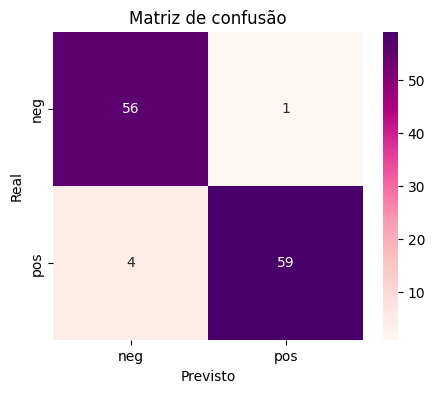

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

melhor_modelo = grid.best_estimator_            # pipeline com os melhores parâmetros, já treinado
y_pred = melhor_modelo.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["negativo", "positivo"]))

# Matriz de confusão como mapa de calor
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="RdPu",
            xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de confusão")
plt.show()

**Como ler:** fora da diagonal estão os erros. Em nosso corpus, os erros costumam vir das reviews **mistas** (uma frase positiva e outra negativa), que confundem até pessoas.

## 5.9 NER — Reconhecimento de entidades nomeadas

NER encontra trechos que são **entidades** (pessoas, organizações, locais, datas, valores). É a base de extração de informação (ex.: ler contratos, notícias, reviews).

### Esquema BIO

Para treinar modelos de NER, cada **token** recebe uma etiqueta:

- `B-TIPO` — **B**egin: começa uma entidade;
- `I-TIPO` — **I**nside: continua a mesma entidade;
- `O` — **O**utside: não é entidade.

| Token | Maria | Silva | trabalha | em | São | Paulo |
|---|---|---|---|---|---|---|
| Tag BIO | B-PER | I-PER | O | O | B-LOC | I-LOC |

### NER com spaCy em português

O modelo `pt_core_news_lg` já vem treinado. Basta processar o texto e ler `doc.ents`:

In [10]:
texto_compra = ("Ontem comprei um iPhone 15 na Magazine Luiza por R$ 5.999. "
                "A entrega foi feita em São Paulo no dia 20 de outubro pela Fedex. "
                "Atendimento da Apple Brasil foi excelente.")

doc = nlp(texto_compra)

print("Entidades encontradas:")
for ent in doc.ents:
    # start_char/end_char = posição da entidade dentro do texto
    print(f"  {ent.text:<22} | {ent.label_:<5} | caracteres {ent.start_char}-{ent.end_char}")

Entidades encontradas:
  iPhone                 | MISC  | caracteres 17-23
  Magazine Luiza         | ORG   | caracteres 30-44
  São Paulo              | LOC   | caracteres 82-91
  Fedex                  | ORG   | caracteres 118-123
  Apple Brasil           | ORG   | caracteres 140-152


In [11]:
# Visualização colorida das entidades dentro do próprio notebook
from spacy import displacy

displacy.render(doc, style="ent")

**Como ler:** cada trecho colorido é uma entidade com seu tipo. O modelo pode errar ou dar rótulos diferentes dos esperados — NER é estatístico.

### Avaliação de NER: por entidade, não por token

Em NER não basta acertar *alguns tokens*: `São Paulo` só conta como correto se **a entidade inteira** (`B-LOC I-LOC`) for prevista. A biblioteca `seqeval` avalia assim, comparando listas de etiquetas BIO:

In [12]:
# 1. Atualiza as ferramentas essenciais de empacotamento
%pip install --upgrade pip setuptools wheel

# 2. Tenta instalar o seqeval novamente
%pip install seqeval

# 3. Agora o import deve funcionar
from seqeval.metrics import classification_report as relatorio_ner

from seqeval.metrics import classification_report as relatorio_ner

# Cada lista interna é uma frase; compara o gabarito (y_true_ner) com a previsão (y_pred_ner)
y_true_ner = [["O", "O", "B-PER", "I-PER", "O", "B-LOC"],
              ["B-ORG", "O", "O", "B-LOC"]]
y_pred_ner = [["O", "O", "B-PER", "I-PER", "O", "B-LOC"],
              ["B-ORG", "O", "O", "O"]]          # errou a última entidade (LOC)

print(relatorio_ner(y_true_ner, y_pred_ner))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 20.7 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 40.8 MB/s eta 0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 80.10.2
    Uninstalling setuptools-80.10.2:
      Successfully uninstalled setuptools-80.10.2
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cpu requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.


  Using cached seqeval-1.2.2.tar.gz (43 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16251 sha256=33658a7fd33f740ca6b5ac572645bdda59fded89c3c5c7d22c06b490da90bbb2
  Stored in directory: /root/.cache/pip/wheels/14/cf/a7/8f28ef376d707ff10e3922899482a2f23ef3002f8a952f47ac
Successfully built seqeval
              precision    recall  f1-score   support

         LOC       1.00      0.50      0.67         2
         ORG       1.00      1.00      1.00         1
         PER       1.00      1.00      1.00         1

   micro avg       1.00      0.75      0.86         4
   macro avg       1.00      0.83      0.89         4
weighted avg       1.00      0.75      0.83         4



**Como ler:** o relatório é por **tipo de entidade** (PER, LOC, ORG). Aqui a previsão errou uma entidade `LOC`, então o recall de `LOC` cai para 50%.

## 5.10 Juntando tudo: sentimento + entidades

Um produto real combina técnicas. A função abaixo usa o classificador (`grid`) para o **sentimento** e o spaCy para as **entidades**, devolvendo um resumo de cada review:

In [13]:
def enriquecer_review(texto):
    """Devolve sentimento (modelo treinado) e entidades (spaCy) de uma review."""
    sentimento = int(grid.predict([texto])[0])                  # 1 = positivo, 0 = negativo
    entidades = [(e.text, e.label_) for e in nlp(texto).ents]   # lista de (trecho, tipo)
    return {"texto": texto, "sentimento": sentimento, "entidades": entidades}

print(enriquecer_review("Adorei o iPhone 15 da Magazine Luiza, entrega rápida em SP!"))

NameError: name 'grid' is not defined

---
# Parte 6 — Modelagem de tópicos (LDA e BERTopic)

Até aqui sabíamos o que procurar (sentimento). Na **modelagem de tópicos** não há rótulos: queremos **descobrir sobre o que o corpus fala**. É aprendizado *não supervisionado*.

- **LDA (Latent Dirichlet Allocation):** cada documento é uma mistura de tópicos; cada tópico, uma mistura de palavras. Usa Bag of Words;
- **BERTopic:** usa **embeddings** de frases, agrupa por similaridade e extrai as palavras-chave de cada grupo. Entende contexto.

In [15]:
# Instala apenas o que é novo nesta parte: pyLDAvis (visualização do LDA), bertopic e sentence-transformers
%pip install -q pyLDAvis bertopic sentence-transformers

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.


## 6.1 LDA com gensim

Passos: (1) criar um **dicionário** (palavra → id); (2) filtrar palavras raras e universais; (3) converter cada documento em BoW; (4) treinar o LDA com um número de tópicos.

Usamos `tokens_limpos` (Parte 2): palavras legíveis, sem stop words.

In [16]:
from gensim import corpora
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel

# 1) Dicionário: mapeia cada palavra para um número
dicionario = corpora.Dictionary(tokens_limpos)

# 2) Remove palavras que aparecem em menos de 10 documentos ou em mais de 50% deles
dicionario.filter_extremes(no_below=10, no_above=0.5)

# 3) Cada documento vira uma lista de (id da palavra, contagem)
corpus_bow = [dicionario.doc2bow(doc) for doc in tokens_limpos]

print("Palavras no dicionário:", len(dicionario))
print("Exemplo (documento 0):", corpus_bow[0][:8])

NameError: name 'tokens_limpos' is not defined

### Quantos tópicos escolher?

O LDA exige **definir o número de tópicos** antes. Uma forma de escolher é a **coerência (c_v)**: mede se as palavras de cada tópico fazem sentido juntas (quanto **maior**, melhor). Treinamos vários valores de *k* e comparamos:

In [ ]:
# Testa k = 2..7 e mostra a coerência de cada um (processes=1 evita travar o computador)
for k in range(2, 8):
    lda_k = LdaModel(corpus=corpus_bow, id2word=dicionario, num_topics=k,
                     passes=10, alpha="auto", eta="auto", random_state=42)
    coerencia = CoherenceModel(model=lda_k, texts=tokens_limpos, dictionary=dicionario,
                               coherence="c_v", processes=1).get_coherence()
    print(f"k = {k} tópicos -> coerência c_v = {coerencia:.3f}")

**Como ler:** procure o *k* com a maior coerência (ou o ponto a partir do qual deixa de melhorar). Os valores aqui são baixos e próximos entre si, e o melhor *k* pode **não coincidir** com os 4 assuntos que usamos para criar o corpus — cada review mistura dois assuntos e sentimentos, e o corpus é pequeno. Em dados reais não conhecemos a resposta; a coerência é só um **guia**, e a decisão final também usa o olhar humano sobre os tópicos.

Treinamos agora o modelo final com 4 tópicos e inspecionamos as palavras de cada um:

In [ ]:
lda = LdaModel(corpus=corpus_bow, id2word=dicionario, num_topics=4,
               passes=20,            # passadas pelo corpus
               alpha="auto",         # distribuição de tópicos por documento aprendida
               eta="auto",           # distribuição de palavras por tópico aprendida
               random_state=42)

# Cada tópico = lista das palavras mais importantes com seus pesos
for idx, topico in lda.print_topics(num_words=8):
    print(f"Tópico {idx}: {topico}")

coerencia_lda = CoherenceModel(model=lda, texts=tokens_limpos, dictionary=dicionario,
                               coherence="c_v", processes=1).get_coherence()
print(f"\nCoerência (c_v) do modelo final: {coerencia_lda:.3f}")

**Como ler:** cada linha é um tópico; os números são os pesos das palavras. **Dar nome** ao tópico é trabalho humano: leia as palavras e resuma (ex.: `entrega`, `chegou`, `entregue`, `pedido` → "logística"). Os tópicos aqui aparecem **misturados** (a palavra `preço` surge em vários): como cada review mistura assuntos e sentimentos e o corpus é pequeno, o LDA não separa tudo de forma limpa. Com milhares de reviews reais, os tópicos tendem a ficar mais nítidos.

### pyLDAvis: explorando os tópicos de forma interativa

O **pyLDAvis** mostra cada tópico como um círculo (tamanho = importância; distância = semelhança) e, ao clicar, as palavras mais relevantes. Funciona dentro do notebook:

In [ ]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

pyLDAvis.enable_notebook()   # permite exibir o gráfico dentro do notebook

try:
    # mds="mmds" evita um erro de números complexos que o método padrão pode gerar em corpora pequenos
    vis = gensimvis.prepare(lda, corpus_bow, dicionario, mds="mmds")
    display(pyLDAvis.display(vis))
except Exception as erro:
    print("Não foi possível montar o pyLDAvis neste ambiente:", erro)

Não foi possível montar o pyLDAvis neste ambiente: name 'lda' is not defined


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Como ler:** círculos **separados** indicam tópicos bem distintos; círculos **sobrepostos** indicam tópicos parecidos (talvez haja tópicos demais). À direita, as barras mostram as palavras mais frequentes do tópico selecionado.

## 6.2 BERTopic

O **BERTopic** funciona em 4 etapas:

1. transforma cada texto em um **embedding** (modelo de frases multilíngue);
2. reduz a dimensão (UMAP);
3. agrupa textos parecidos (HDBSCAN) — cada grupo é um tópico, e o grupo `-1` reúne os "outliers" (sem tópico claro);
4. extrai as **palavras-chave** de cada grupo (c-TF-IDF).

Ele **descobre o número de tópicos sozinho** e entende contexto, mas é **mais pesado**: baixa um modelo (~470 MB na 1ª vez) e usa bastante memória.

> **Se o seu computador estiver lento, mude `RODAR_BERTOPIC` para `False`.** As células do BERTopic serão ignoradas e o restante do notebook continua funcionando.

In [ ]:
RODAR_BERTOPIC = True     # mude para False se faltar memória ou internet

topic_model = None        # será preenchido abaixo, se RODAR_BERTOPIC for True
embedder = None

if RODAR_BERTOPIC:
    from bertopic import BERTopic
    from sentence_transformers import SentenceTransformer

    # Modelo que transforma frases (em vários idiomas, inclusive português) em embeddings
    embedder = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

    topic_model = BERTopic(
        embedding_model=embedder,
        language="multilingual",
        min_topic_size=20,       # só considera tópicos com 20+ documentos
        nr_topics="auto",        # reduz/une tópicos parecidos automaticamente
    )

    # Usa o texto original (BERTopic faz o próprio tratamento), não os tokens limpos
    topics, probs = topic_model.fit_transform(reviews)

    # Tabela-resumo: -1 = outliers; as demais linhas são os tópicos encontrados
    print(topic_model.get_topic_info().head(10))
else:
    print("BERTopic desativado (RODAR_BERTOPIC = False).")

**Como ler a tabela:** `Topic` é o id (`-1` = sem tópico claro), `Count` é quantos documentos pertencem a ele e `Name` mostra as primeiras palavras-chave.

### Visualizações do BERTopic

O BERTopic gera gráficos interativos (Plotly) parecidos com o pyLDAvis. Cada um está protegido por `try/except`: com poucos tópicos, alguns gráficos não podem ser gerados, e isso não deve interromper o notebook.

In [ ]:
if topic_model is not None:
    graficos = {
        "Mapa de tópicos (2D)":            lambda: topic_model.visualize_topics(),
        "Palavras-chave por tópico":       lambda: topic_model.visualize_barchart(top_n_topics=10),
        "Hierarquia de tópicos":           lambda: topic_model.visualize_hierarchy(),
        "Similaridade entre tópicos":      lambda: topic_model.visualize_heatmap(),
    }
    for titulo, gerar in graficos.items():
        try:
            print(titulo)
            gerar().show()
        except Exception as erro:
            print(f"  (não foi possível gerar este gráfico: {erro})")
else:
    print("BERTopic desativado.")

**Como ler:** o *mapa* mostra tópicos como bolhas (distância = semelhança); o *gráfico de barras* lista as palavras-chave; a *hierarquia* mostra quais tópicos poderiam ser unidos; o *heatmap* mostra a similaridade entre pares de tópicos.

## 6.3 BERTopic x LDA

| | LDA | BERTopic |
|---|---|---|
| Entrada | contagem de palavras (BoW) | embeddings de frases |
| Nº de tópicos | você define | descobre sozinho |
| Contexto/sinônimos | não entende | entende |
| Velocidade / memória | leve e rápido | mais pesado |
| Interpretação | palavras com pesos | palavras-chave + gráficos |

Vamos comparar **tempo** e **coerência** nos mesmos dados:

In [ ]:
import time

# --- LDA: tempo só do treino ---
t0 = time.time()
lda_cmp = LdaModel(corpus=corpus_bow, id2word=dicionario, num_topics=4,
                   passes=20, random_state=42)
tempo_lda = time.time() - t0
coh_lda = CoherenceModel(model=lda_cmp, texts=tokens_limpos, dictionary=dicionario,
                         coherence="c_v", processes=1).get_coherence()

print(f"{'Modelo':<10} {'Tempo (s)':>10} {'Coerência':>10}")
print(f"{'LDA':<10} {tempo_lda:>10.1f} {coh_lda:>10.3f}")

# --- BERTopic: tempo do treino (usa o modelo já carregado) e coerência das palavras-chave ---
if RODAR_BERTOPIC and topic_model is not None:
    t0 = time.time()
    topic_model_cmp = BERTopic(embedding_model=embedder, language="multilingual", min_topic_size=20)
    topic_model_cmp.fit_transform(reviews)
    tempo_bert = time.time() - t0

    # Palavras-chave de cada tópico (exceto o -1), mantendo só as que existem no dicionário do LDA
    top_words = []
    for t in topic_model_cmp.get_topics():
        if t == -1:
            continue
        palavras_t = [w for w, _ in topic_model_cmp.get_topic(t)[:10] if w in dicionario.token2id]
        if len(palavras_t) >= 2:
            top_words.append(palavras_t)

    if len(top_words) >= 2:
        coh_bert = CoherenceModel(topics=top_words, texts=tokens_limpos, dictionary=dicionario,
                                  coherence="c_v", processes=1).get_coherence()
        print(f"{'BERTopic':<10} {tempo_bert:>10.1f} {coh_bert:>10.3f}")
    else:
        print(f"{'BERTopic':<10} {tempo_bert:>10.1f}   (poucos tópicos para calcular coerência)")
else:
    print("BERTopic desativado: comparação apenas do LDA.")

**Como ler:** em corpora grandes e reais, o BERTopic costuma ter **coerência maior** e tópicos mais legíveis, mas leva **muito mais tempo** que o LDA. Em corpora pequenos como o nosso, os dois podem ficar próximos. Escolha conforme o contexto: LDA para rapidez e simplicidade; BERTopic para qualidade e textos curtos/informais.

---
# Resumo e próximos passos

| Etapa | Técnica | Quando usar |
|---|---|---|
| Limpeza | regex, contrações, acentos | sempre, adaptando à tarefa |
| Tokenização | NLTK, spaCy, subwords (BPE) | spaCy/NLTK no dia a dia; subwords para modelos modernos |
| Redução | stemming (rápido) x lematização (preciso) | busca/baseline x tarefas semânticas |
| Vetorização esparsa | BoW, n-gramas, TF-IDF | baseline forte, rápido e interpretável |
| Vetorização densa | Word2Vec, FastText | semântica e palavras desconhecidas |
| Classificação | Naive Bayes, Regressão Logística + Pipeline | sentimento, categorias; ajuste com GridSearch |
| Extração | NER (spaCy) | achar pessoas, locais, organizações, valores |
| Tópicos | LDA, BERTopic | descobrir temas sem rótulos |

**Para ir além:** troque os dados sintéticos por um corpus real, experimente transformers (BERTimbau) para classificação e compare com o baseline TF-IDF + Regressão Logística.